# 5. Evaluation
The classifier and feature set were chosen using development folds in Modeling.
We now assess that fixed choice on the 1,298 later purchases reserved for the
outer holdout. Binary F1 is primary; precision, recall, accuracy and the error
counts explain what that result means.

In [1]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay

sns.set_theme(style="whitegrid")

## Load the model and holdout
Both matrices use development preparation parameters. The selected inputs
are listed in the CSV saved by Modeling.

In [2]:
target = "repeat_purchase_90d"
train = pd.read_csv("../data/prepared/train.csv", index_col="ID")
valid = pd.read_csv("../data/prepared/valid.csv", index_col="ID")
model = joblib.load("../results/development_model.joblib")
cols = pd.read_csv("../results/selected_features.csv")["feature"].tolist()

X_train = train.drop(columns=target)
y_train = train[target]
X_valid = valid.drop(columns=target)
y_valid = valid[target]

In [3]:
pred = model.predict(X_valid[cols])
prob = model.predict_proba(X_valid[cols])[:, 1]
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_valid)

## Compare with the same baseline
The majority class is determined from development labels. We compare both
solutions on exactly the same holdout rows, using their default decision rule.

In [4]:
scores = pd.DataFrame(index=["Baseline", "Random forest"])
scores["F1"] = [f1_score(y_valid, base_pred), f1_score(y_valid, pred)]
scores["precision"] = [precision_score(y_valid, base_pred, zero_division=0),
                       precision_score(y_valid, pred, zero_division=0)]
scores["recall"] = [recall_score(y_valid, base_pred, zero_division=0),
                    recall_score(y_valid, pred, zero_division=0)]
scores["accuracy"] = [accuracy_score(y_valid, base_pred), accuracy_score(y_valid, pred)]
scores.index.name = "model"
scores = scores.reset_index()
scores.round(4)

,model,F1,precision,recall,accuracy
0,Baseline,0.7525,0.6032,1.0000,0.6032
1,Random forest,0.7778,0.7869,0.7688,0.7350


The fixed forest achieves **F1 0.7778**, compared with **0.7525** for
the baseline: an absolute gain of about 2.5 F1 percentage points.
Precision is 0.7869 and recall is 0.7688. The baseline reaches recall 1
by predicting repeat purchase for everyone, but its precision is only
0.6032. The forest improves the balance rather than either measure alone.

## Types of error
False positives predict a repeat purchase that does not occur within 90 days.
False negatives miss a customer who does repeat. The brief supplies no contact
costs or margins, so these counts cannot be translated into a profit estimate.

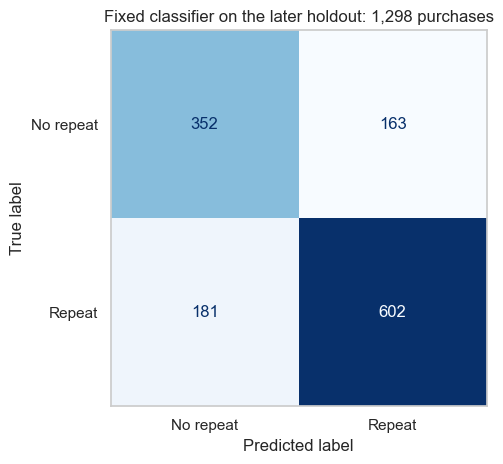

In [5]:
ConfusionMatrixDisplay.from_predictions(y_valid, pred, labels=[0, 1],
                                        display_labels=["No repeat", "Repeat"],
                                        cmap="Blues", colorbar=False)
plt.grid(False)
plt.title("Fixed classifier on the later holdout: 1,298 purchases")
plt.tight_layout()
plt.show()

The model correctly classifies 602 repeat purchases and 352 non-repeat
purchases. There are 163 false positives and 181 false negatives.
These are purchase-level counts in this specific later period.

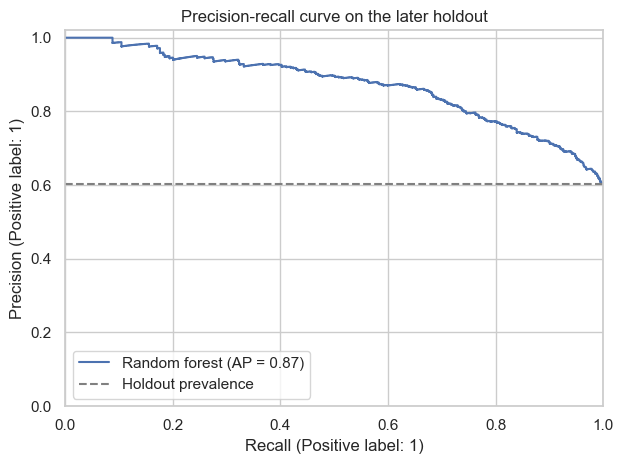

In [6]:
PrecisionRecallDisplay.from_predictions(y_valid, prob, name="Random forest")
plt.axhline(y_valid.mean(), color="grey", linestyle="--", label="Holdout prevalence")
plt.title("Precision-recall curve on the later holdout")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend()
plt.tight_layout()
plt.show()

The curve describes the fixed model's scores. We do not use it to choose a new
threshold after inspecting this holdout. Average precision shown in the plot
is a complementary ranking measure, not the Kaggle F1 score.

## Customers seen in development and first purchases
We distinguish customers seen in development from customers absent from it.
Being absent from development does not mean that this is a first purchase:
the supplied history can include earlier purchases outside that fitting period.
First purchases are identified separately by `prior_purchase_count == 0`.
We inspect these groups without modifying the selected solution. Customers
repeat across rows, so purchase-level scores are not independent customer trials.

In [7]:
raw = pd.read_csv("../data/clean/train.csv", parse_dates=["purchase_date"])
raw = raw.set_index("ID")
meta = raw.loc[valid.index]
seen = meta["customer_id"].isin(raw.loc[train.index, "customer_id"])
first = meta["prior_purchase_count"] == 0

res = pd.DataFrame(index=valid.index)
res["actual"] = y_valid
res["prediction"] = pred
res["probability"] = prob

In [8]:
groups = [("Seen in development", seen), ("Unseen in development", ~seen),
          ("First purchase", first), ("Previous history", ~first)]
rows = []
for name, mask in groups:
    if mask.sum() > 0:
        y_group = res.loc[mask, "actual"]
        pred_group = res.loc[mask, "prediction"]
        pos = int(y_group.sum())
        tp = int(((y_group == 1) & (pred_group == 1)).sum())
        f1 = f1_score(y_group, pred_group, zero_division=0)
        rows.append([name, len(y_group), pos, tp, y_group.mean(), f1])
groups = pd.DataFrame(rows, columns=["group", "purchases", "positives",
                                    "true positives", "repeat share", "F1"])
groups.round(4)

,group,purchases,positives,true positives,repeat share,F1
0,Seen in development,1153,707,564,0.6132,0.7910
1,Unseen in development,145,76,38,0.5241,0.6230
2,First purchase,44,12,0,0.2727,0.0000
3,Previous history,1254,771,602,0.6148,0.7839


F1 is 0.7910 for customers seen in development and 0.6230 for those unseen
in development. Of the 145 purchases in the latter group, 101 already have
supplied purchase history; they should not be called first purchases.
The 44 first purchases include 12 positive cases, with no true positives
from the model (F1 = 0). This is a concrete weakness in this holdout.
Its small sample limits generalisation, and a cold-start strategy should
be investigated using development data in the final project. We do not
change the chosen solution after seeing these holdout results.

These are two separate partitions: seen/unseen development customers and first/returning
purchases. They overlap across partitions and must not be added together.
Small group scores deserve particular caution.

In [9]:
errors = res.loc[res["actual"] != res["prediction"]].copy()
errors["prior_purchase_count"] = meta.loc[errors.index, "prior_purchase_count"]
errors["days_since_previous_purchase"] = meta.loc[errors.index, "days_since_previous_purchase"]
errors.sort_values("probability", ascending=False).head(10).round(3)

,actual,prediction,probability,prior_purchase_count,days_since_previous_purchase
ID,,,,,
10007078,0,1,0.913,63.0,98.0
10006602,0,1,0.899,276.0,20.0
10003296,0,1,0.850,82.0,77.0
10005666,0,1,0.839,106.0,36.0
10001929,0,1,0.833,74.0,NaN
10006201,0,1,0.831,79.0,77.0
10007330,0,1,0.824,57.0,48.0
10007452,0,1,0.815,58.0,66.0
10004915,0,1,0.803,14.0,46.0


## Save the assessed result
The metrics and holdout predictions allow the report to be checked against
the notebook. No Kaggle score has been observed or substituted for local F1.

In [10]:
scores.to_csv("../results/holdout_metrics.csv", index=False)
res.to_csv("../results/holdout_predictions.csv", index=True)
groups.to_csv("../results/holdout_groups.csv", index=False)

## Limits and next step
The earlier group notebook explored the full training file before this
protocol was set, so the holdout is not a completely untouched dataset.
It is one later period, not evidence of stability in every future period.

Cleaning assumes historical totals and counts are reliable. Customer
attributes are supplied as a single table without historical snapshots.
Anonymised calendar features and rare categories need further study in the
final project. We make no causal or profit claims.

Next: [Deployment](06_Deployment.ipynb), which refits the chosen method on all
eligible labelled purchases and creates the submission file.